### Harmonic Oscillator Path Integral—Brennan Newman

- TSN: 200075102
- *x<sub>start</sub>*: -0.51

In [ ]:
# %pip install numpy matplotlib pillow

In [4]:
# Import packages
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

In [5]:
T_end = 2 * np.pi
NT = 128
ND = 600
x = np.linspace(-4, 4, ND + 1)
t = np.linspace(0, T_end, NT + 1)
dx = x[1] - x[0]
dt = T_end / NT

print("Positions:", x.shape, "dx:", dx)
print("Times:", t.shape, "dt:", dt)

Positions: (601,) dx: 0.013333333333333197
Times: (129,) dt: 0.04908738521234052


In [6]:
# Define Gaussian, xstart, and print them
def gaussian(x, xstart, alpha, k0):
    return (alpha / np.pi)**0.25 * np.exp(
        -alpha / 2 * (x - xstart)**2 + 1j * k0 * (x - xstart)
    )

alpha = 2
xstart = (-1)**1 * (0.5 + 2/200)
k0 = 0
psi0 = gaussian(x, xstart, alpha, k0)
P0 = np.abs(psi0)**2
norm0 = dx * np.sum(P0)
print("x_start: ", xstart)
print("Initial norm:", norm0)

x_start:  -0.51
Initial norm: 0.9999999999986496


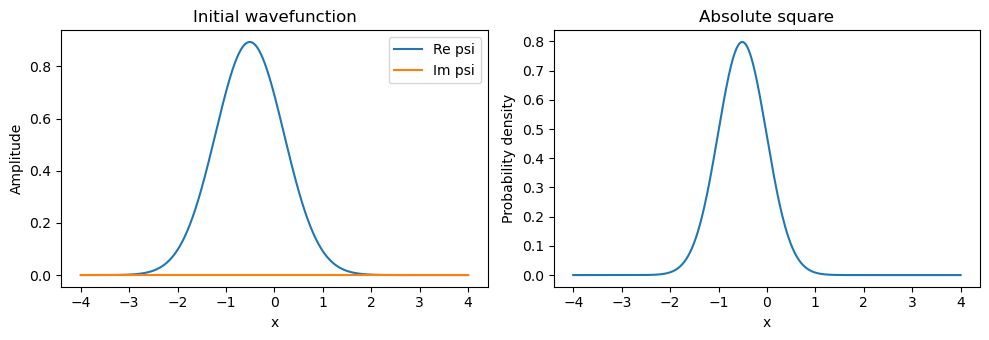

In [7]:
# Plotting waveform
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(x, psi0.real, label="Real psi")
axes[0].plot(x, psi0.imag, label="Imaginary psi")
axes[0].set(xlabel="x", ylabel="Amplitude", title="Initial wavefunction")
axes[0].legend()
axes[1].plot(x, P0)
axes[1].set(xlabel="x", ylabel="Probability density", title="Absolute square")
fig.tight_layout()
plt.show()

## Problem A
Creating the kernel and propagator.

In [47]:
# Defining the Harmonic Oscillator kernel
m = 1
omega = 1
hbar = 1
def harmonic_kernel(x_dest, x_src, step):
    return (
        np.sqrt((m * omega) / (2 * np.pi * 1j * hbar * np.sin(omega * step)))
        / np.exp(((1j * m * omega) / (2 * hbar * np.sin(omega * step))) * ((x_src**2 + x_dest**2) * np.cos(omega * step) - 2 * x_src * x_dest))
    )
# Creating the propagator
K_eps = harmonic_kernel(x[:, None], x[None, :], dt)
# Finding the 8-step evolution matrix
U = dx * K_eps
K_8eps = np.linalg.matrix_power(U, 8) / dx
print("Truncated 8-step Evolution Matrix:\n", K_8eps)

Truncated 8-step Evolution Matrix:
 [[-0.05955846-0.0178667j  -0.0757611 -0.0217024j  -0.07967385-0.05414053j
  ... -0.46505982+0.30932634j -0.35439299+0.42735575j
  -0.21687407+0.50917202j]
 [-0.0757611 -0.0217024j  -0.0896081 -0.03330227j -0.08308486-0.06724787j
  ... -0.53404108+0.16837676j -0.46141968+0.31131639j
  -0.35439299+0.42735575j]
 [-0.07967385-0.05414053j -0.08308486-0.06724787j -0.06226964-0.09303051j
  ... -0.56407376+0.01040964j -0.53404108+0.16837676j
  -0.46505982+0.30932634j]
 ...
 [-0.46505982+0.30932634j -0.53404108+0.16837676j -0.56407376+0.01040964j
  ... -0.06226964-0.09303051j -0.08308486-0.06724787j
  -0.07967385-0.05414053j]
 [-0.35439299+0.42735575j -0.46141968+0.31131639j -0.53404108+0.16837676j
  ... -0.08308486-0.06724787j -0.0896081 -0.03330227j
  -0.0757611 -0.0217024j ]
 [-0.21687407+0.50917202j -0.35439299+0.42735575j -0.46505982+0.30932634j
  ... -0.07967385-0.05414053j -0.0757611 -0.0217024j
  -0.05955846-0.0178667j ]]


## Problem B
a) Evolving the particle

In [48]:
# Evolving the state of the particle for one full period
def evolve(U, initial_state, steps):
    states = np.empty((steps + 1, initial_state.size), dtype=complex)
    states[0] = initial_state
    for n in range(steps):
        states[n + 1] = U @ states[n]
    return states

psi = evolve(U, psi0, NT)
P = np.abs(psi)**2
norm = dx * np.sum(P, axis=1)
x_mean = dx * np.sum(P * x[None, :], axis=1)
print("States:", psi.shape, "Mean positions:", x_mean.shape)

States: (129, 601) Mean positions: (129,)


b) Graphing its mean position as a function of time

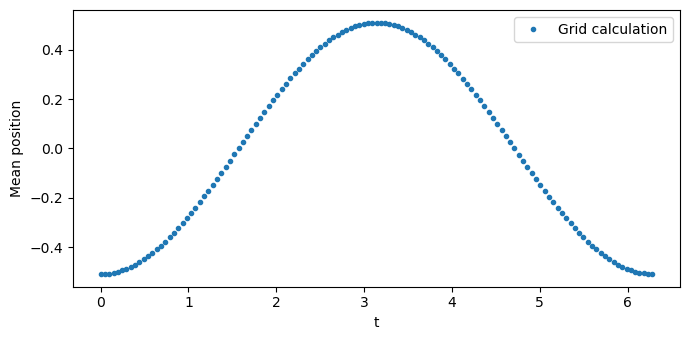

In [49]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, x_mean, "o", markersize=3, label="Grid calculation")
ax.set(xlabel="t", ylabel="Mean position")
ax.legend()
fig.tight_layout()
plt.show()

## Problem C
Calcuting the mean energy ⟨E⟩, mean kinetic energy ⟨K⟩, and mean potential energy ⟨V⟩.

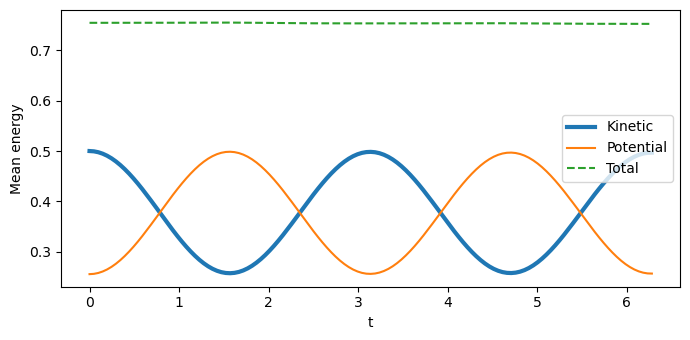

In [50]:
dpsi_dx = np.gradient(psi, dx, axis=1, edge_order=2)
V_grid = x**2 / 2
K_mean = 0.5 * dx * np.sum(np.abs(dpsi_dx)**2, axis=1)
V_mean = dx * np.sum(P * V_grid[None, :], axis=1)
E_mean = K_mean + V_mean

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, K_mean, label="Kinetic", linewidth=3)
ax.plot(t, V_mean, label="Potential")
ax.plot(t, E_mean, "--", label="Total")
ax.set(xlabel="t", ylabel="Mean energy")
ax.legend()
fig.tight_layout()
plt.show()

## Problem D
Calculate the probability amplitude at certain snapshots.

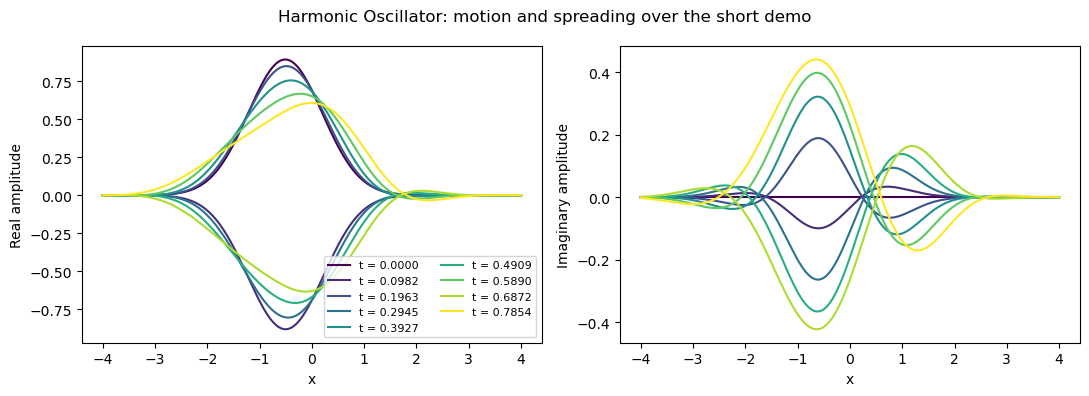

In [51]:
# Selecting snapshots
snapshot_indices = 2 * np.arange(9)
snapshot_times = t[snapshot_indices]
P_snapshots = P[snapshot_indices]
# Plotting snapshots
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(snapshot_indices)))
for index, color in zip(snapshot_indices, colors):
    label = f"t = {t[index]:.4f}"
    axes[0].plot(x, psi[index].real, color=color, label=label)
    axes[1].plot(x, psi[index].imag, color=color)
axes[0].set(xlabel="x", ylabel="Real amplitude")
axes[1].set(xlabel="x", ylabel="Imaginary amplitude")
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle("Harmonic Oscillator: motion and spreading over the short demo")
fig.tight_layout()
plt.show()

## Problem E
Animating the time evolution of probability.

In [52]:
# Creating the animation
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
real_line, = axes[0].plot(x, psi[0].real, label="Re psi")
imag_line, = axes[0].plot(x, psi[0].imag, label="Im psi")
density_line, = axes[1].plot(x, P[0])
amplitude_limit = 1.1 * np.max(np.abs(psi))
axes[0].set(xlim=(x[0], x[-1]), ylim=(-amplitude_limit, amplitude_limit),
            xlabel="x", ylabel="Amplitude")
axes[0].legend(loc="upper right")
axes[1].set(xlim=(x[0], x[-1]), ylim=(0, 1.1 * P.max()),
            xlabel="x", ylabel="Probability density")
time_label = fig.suptitle("")
fig.tight_layout(rect=(0, 0, 1, 0.9))

def update_frame(n):
    real_line.set_ydata(psi[n].real)
    imag_line.set_ydata(psi[n].imag)
    density_line.set_ydata(P[n])
    time_label.set_text(f"Harmonic Oscillator: t = {t[n]:.4f}; norm = {norm[n]:.6f}")
    return real_line, imag_line, density_line, time_label

animation = FuncAnimation(fig, update_frame, frames=len(t), interval=1000 / 6)
gif_path = Path("harmonic_oscillator_demo.gif")
animation.save(gif_path, writer=PillowWriter(fps=6), dpi=80)
plt.close(fig)
print("Saved:", gif_path.resolve(), "with", len(t), "frames")

Saved: /home/bdnewman/phys142-lab04/phys142/homework/assignment1/harmonic_oscillator_demo.gif with 129 frames


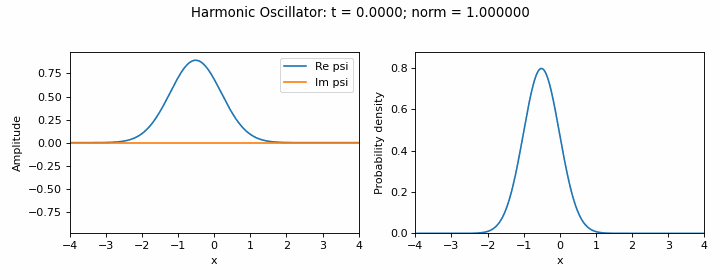

In [53]:
# Displaying the gif
display(Image(filename=str(gif_path)))

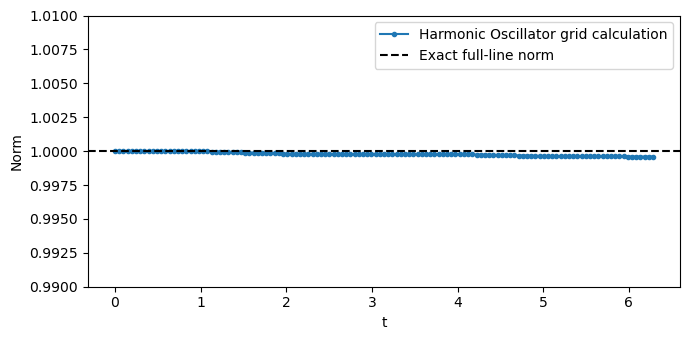

In [54]:
# Calculating the state norm
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, norm, "o-", markersize=3, label="Harmonic Oscillator grid calculation")
ax.axhline(1, color="black", linestyle="--", label="Exact full-line norm")
ax.set(xlabel="t", ylabel="Norm", ylim=(0.99, 1.01))
ax.legend()
fig.tight_layout()
plt.show()

## Problem F
$$\mathscr{N}(t)=\Delta x\sum_i\left|\psi_t(x_i)\right|^2$$
Compute the above norm over one full period in three cases:

i) $\epsilon=T_0/16$ with $N_D = 600$

i) $\epsilon=T_0/512$ with $N_D = 600$

i) $\epsilon=T_0/128$ with $N_D = 150$

In [61]:
# i
# Creating the propagator
K_8epsi = np.linalg.matrix_power(harmonic_kernel(x[:, None], x[None, :], 16 * dt), 8) * dx**7
# Evolution
def evolve_i(K_epsi, initial_state, steps):
    states = np.empty((steps + 1, initial_state.size), dtype=complex)
    states[0] = initial_state
    for n in range(steps):
        states[n + 1] = U @ states[n]
    return states

psi_i = evolve(K_epsi, psi0, NT)
P_i = np.abs(psi)**2
norm_i = dx * np.sum(P, axis=1)
x_mean_i = dx * np.sum(P * x[None, :], axis=1)
# ii
# Creating the propagator
K_8epsii = np.linalg.matrix_power(harmonic_kernel(x[:, None], x[None, :], 0.5 * dt), 8) * dx**7
# Evolution
def evolve_ii(K_epsii, initial_state, steps):
    states = np.empty((steps + 1, initial_state.size), dtype=complex)
    states[0] = initial_state
    for n in range(steps):
        states[n + 1] = U @ states[n]
    return states

psi_ii = evolve(K_epsii, psi0, NT)
P_ii = np.abs(psi)**2
norm_ii = dx * np.sum(P, axis=1)
x_mean_ii = dx * np.sum(P * x[None, :], axis=1)
# iii
# Creating the propagator
x_iii = np.linspace(-4, 4, 151)
K_8epsiii = np.linalg.matrix_power(harmonic_kernel(x_iii[:, None], x_iii[None, :], dt), 8) * dx**7
# Evolution
def evolve_iii(K_epsiii, initial_state, steps):
    states = np.empty((steps + 1, initial_state.size), dtype=complex)
    states[0] = initial_state
    for n in range(steps):
        states[n + 1] = U @ states[n]
    return states

psi_iii = evolve(K_epsi, psi0, NT)
P_iii = np.abs(psi)**2
norm_iii = dx * np.sum(P, axis=1)
x_mean_iii = dx * np.sum(P * x[None, :], axis=1)

Calculating and plotting the norm

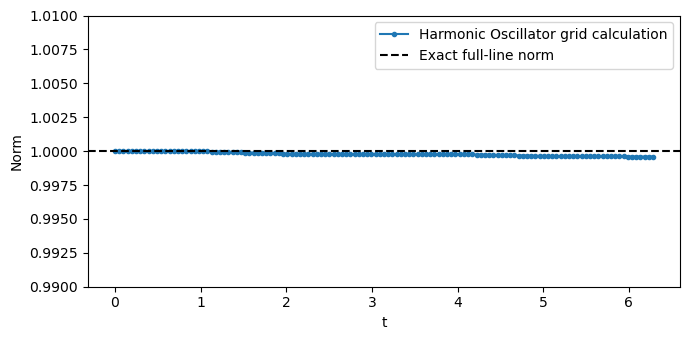

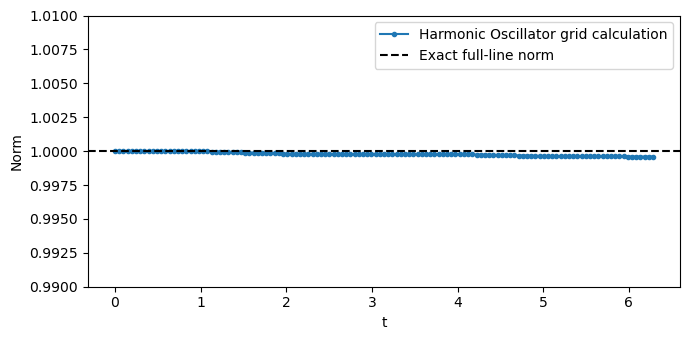

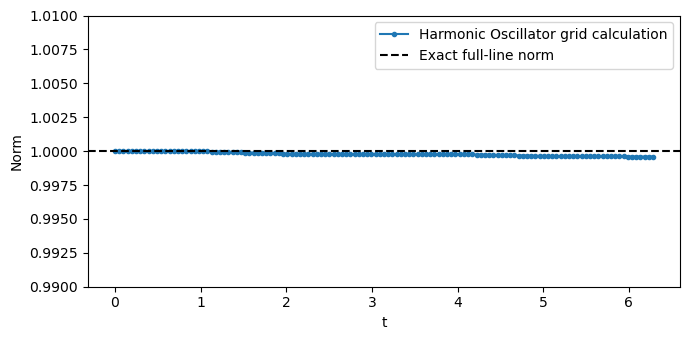

In [60]:
# Calculating the state norm
# i
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, norm_i, "o-", markersize=3, label="Harmonic Oscillator grid calculation")
ax.axhline(1, color="black", linestyle="--", label="Exact full-line norm")
ax.set(xlabel="t", ylabel="Norm", ylim=(0.99, 1.01))
ax.legend()
fig.tight_layout()
plt.show()
# ii
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, norm_ii, "o-", markersize=3, label="Harmonic Oscillator grid calculation")
ax.axhline(1, color="black", linestyle="--", label="Exact full-line norm")
ax.set(xlabel="t", ylabel="Norm", ylim=(0.99, 1.01))
ax.legend()
fig.tight_layout()
plt.show()
# ii
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, norm_iii, "o-", markersize=3, label="Harmonic Oscillator grid calculation")
ax.axhline(1, color="black", linestyle="--", label="Exact full-line norm")
ax.set(xlabel="t", ylabel="Norm", ylim=(0.99, 1.01))
ax.legend()
fig.tight_layout()
plt.show()

## AI Use Appendix

I used the Google AI overview for debugging (catching typos because the DataHub JupyterLab can't do it on its own) and figuring out how to submit my report. This report was just a Jupyter notebook, so I Googled how to export it as a pdf.

In [57]:
# Writing the JSON file
results = {
    "tsn": "200075102",
    "x_start": xstart,
    "K8eps_row": {"re": K_8eps[300].real.tolist(),
    "im": K_8eps[300].imag.tolist()},
    "x_mean": x_mean.tolist(),
    "V": V_mean.tolist(), "K": K_mean.tolist(), "E": E_mean.tolist(),
    "P": [P_t.tolist() for P_t in P_snapshots],
}
with open("results.json", "w") as f:
    json.dump(results, f)